# Criteo benchmark: S/T/X meta-learners with bootstrap confidence intervals

日本語要約: Criteo Uplift Prediction Dataset v2.1（1,390万行のランダム化広告実験）
から層化抽出した 100 万行で、S/T/X メタラーナーを比較する。評価指標
（Qini 係数・AUUC・uplift@10%）にはすべてブートストラップ 95% 信頼区間を付け、
さらに同一リサンプルによる対応差の CI で学習器間の差を直接検定する。
結論は「区間が重なる場合は勝者なし」と正直に読む。ノートブック 01 で
検証済みの評価基盤をそのまま使う。

This notebook needs the raw Criteo file. Without it (for example in CI),
every computation cell is skipped with a message; run
`python scripts/download_data.py` (about 311 MB) to reproduce the results.

**What this notebook shows**

- EDA of the Criteo uplift experiment: an 85/15 randomized split, a 4.7%
  `visit` rate and a 0.29% `conversion` rate, which is why `visit` is the
  benchmark outcome.
- A deterministic, treatment-stratified 1M-row subsample and a 50/50
  train/test split.
- S-, T- and X-learners compared on Qini coefficient, AUUC and uplift@10%,
  each with a bootstrap 95% CI, plus paired bootstrap CIs for the
  differences between learners.
- Qini curves with CI bands, an uplift-by-decile calibration plot, and an
  honest reading: where intervals overlap, no winner is declared.

In [1]:
import gc
import os
import time

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

from uplift_bench.data import criteo_available, load_criteo, subsample, train_test_split_df
from uplift_bench.learners import SLearner, TLearner, XLearner
from uplift_bench.metrics import (
    auuc,
    bootstrap_curve_band,
    qini_coefficient,
    qini_curve,
    uplift_at_k,
    uplift_by_decile,
)
from uplift_bench.plotting import plot_curves_with_bands, plot_uplift_by_decile, set_style
from uplift_bench.synthetic import FEATURES

set_style()
SEED = 42

CI = bool(os.environ.get("CI"))
N_SUBSAMPLE = 1_000_000
N_BOOT = 60 if CI else 300

HAS_DATA = criteo_available()
if HAS_DATA:
    print(f"raw Criteo file found; settings: n_subsample={N_SUBSAMPLE}, n_boot={N_BOOT}")
else:
    print(
        "Raw Criteo file not found; all computation cells below are skipped.\n"
        "Run: python scripts/download_data.py"
    )

raw Criteo file found; settings: n_subsample=1000000, n_boot=300


## 1. The dataset and its experiment

The Criteo Uplift Prediction Dataset v2.1 (Diemert et al., AdKDD 2018)
records a large randomized advertising experiment: each row is a user,
`treatment` marks whether the user was eligible to be targeted, and the
outcomes are a site `visit` and a `conversion` within the attribution
window. The 12 features `f0`-`f11` are anonymized and undocumented by
design. `exposure` marks treated users who actually saw an ad; using it as
a treatment indicator would break randomization (exposure is a
post-assignment event), so this benchmark keeps intent-to-treat.

In [2]:
if HAS_DATA:
    t0 = time.time()
    full = load_criteo()
    print(f"loaded {len(full):,} rows in {time.time() - t0:.0f}s")

loaded 13,979,592 rows in 10s


In [3]:
if HAS_DATA:

    def _arm_summary(df: pd.DataFrame) -> pd.DataFrame:
        by_arm = df.groupby("treatment")[["visit", "conversion", "exposure"]].mean()
        counts = df["treatment"].value_counts().rename("rows")
        return pd.concat([counts, by_arm], axis=1)

    print(f"treated fraction: {full['treatment'].mean():.4f}")
    print(_arm_summary(full).round(5))

treated fraction: 0.8500


               rows    visit  conversion  exposure
treatment                                         
1          11882655  0.04854     0.00309   0.03604
0           2096937  0.03820     0.00194   0.00000


Both outcomes are rare, but `conversion` is another order of magnitude
rarer. On a tutorial-scale subsample the conversion counts per decile
become too small for stable uplift estimates, so `visit` is the modeling
outcome and `conversion` appears only as context. The absolute treatment
effect on `visit` (about one percentage point) is what the models try to
allocate to the right users.

In [4]:
if HAS_DATA:

    def diff_in_means_ci(df: pd.DataFrame, outcome: str) -> str:
        yt = df.loc[df["treatment"] == 1, outcome]
        yc = df.loc[df["treatment"] == 0, outcome]
        ate = yt.mean() - yc.mean()
        se = np.sqrt(yt.var() / len(yt) + yc.var() / len(yc))
        return f"{outcome}: ATE = {ate:.5f} (95% CI {ate - 1.96 * se:.5f} .. {ate + 1.96 * se:.5f})"

    print("difference in means on the full 13.9M rows:")
    print(" ", diff_in_means_ci(full, "visit"))
    print(" ", diff_in_means_ci(full, "conversion"))

difference in means on the full 13.9M rows:
  visit: ATE = 0.01034 (95% CI 0.01006 .. 0.01063)
  conversion: ATE = 0.00115 (95% CI 0.00108 .. 0.00122)


## 2. Deterministic subsample and split

The full frame holds 13.9M rows; the benchmark uses a seeded,
treatment-stratified subsample of 1M rows so that the whole notebook runs
in minutes while the treated fraction stays at 0.85 to within one row.
Everything downstream (split, models, bootstrap) is seeded as well, so the
committed numbers reproduce exactly.

In [5]:
if HAS_DATA:
    sample = subsample(full, N_SUBSAMPLE, seed=SEED)
    del full
    gc.collect()
    train, test = train_test_split_df(sample, test_size=0.5, seed=SEED)
    print(f"subsample: {len(sample):,} rows, treated fraction {sample['treatment'].mean():.4f}")
    print(f"train {len(train):,} / test {len(test):,}")
    print(_arm_summary(sample).round(5))

subsample: 1,000,000 rows, treated fraction 0.8500
train 500,000 / test 500,000
             rows    visit  conversion  exposure
treatment                                       
1          850000  0.04828     0.00297   0.03612
0          150000  0.03783     0.00177   0.00000


## 3. Fit the three meta-learners

Same setup as validated in notebook 01: a shared, regularized gradient
boosting base model (shallow trees, large leaves, because the outcome is
rare), and for the X-learner the constant empirical propensity, which is
the correct choice under randomized assignment; a fitted propensity model
could only add variance here.

In [6]:
if HAS_DATA:
    x_train, t_train = train[FEATURES].to_numpy(), train["treatment"].to_numpy()
    y_train = train["visit"].to_numpy()
    x_test, t_test = test[FEATURES].to_numpy(), test["treatment"].to_numpy()
    y_test = test["visit"].to_numpy()

    base = HistGradientBoostingClassifier(
        random_state=SEED, max_depth=3, min_samples_leaf=500, max_iter=150
    )
    effect = HistGradientBoostingRegressor(
        random_state=SEED, max_depth=3, min_samples_leaf=500, max_iter=150
    )
    learners = {
        "S-learner": SLearner(base),
        "T-learner": TLearner(base),
        "X-learner": XLearner(base, effect, propensity="constant"),
    }
    scores = {}
    for name, learner in learners.items():
        t0 = time.time()
        scores[name] = learner.fit(x_train, t_train, y_train).predict_uplift(x_test)
        print(f"{name}: fitted in {time.time() - t0:.0f}s")

S-learner: fitted in 1s


T-learner: fitted in 1s


X-learner: fitted in 2s


## 4. Metrics with bootstrap confidence intervals

One set of stratified bootstrap resamples of the test set is shared by all
learners and all metrics. Sharing resamples has two benefits: the per-metric
CIs are computed consistently, and for any two learners the *paired*
distribution of differences is available, which is the statistically honest
way to compare models evaluated on the same rows.

One easy-to-miss detail: each resample is shuffled after the stratified
draw. Gradient-boosted scores contain ties, and a resample assembled as
"all control rows, then all treated rows" would put control rows first
inside every tied block of the ranking, biasing Qini-style metrics upward
or downward depending on the learner. The shuffle removes that artifact
(the full-sample estimate is unaffected because the subsample was already
shuffled).

In [7]:
if HAS_DATA:
    rng = np.random.default_rng(SEED)
    idx_by_arm = [np.flatnonzero(t_test == arm) for arm in (0, 1)]
    metric_fns = {
        "qini": qini_coefficient,
        "auuc": auuc,
        "uplift@10%": lambda y, t, s: uplift_at_k(y, t, s, k=0.10),
    }

    t0 = time.time()
    boot = np.empty((N_BOOT, len(learners), len(metric_fns)))
    for b in range(N_BOOT):
        take = np.concatenate([rng.choice(idx, size=idx.shape[0]) for idx in idx_by_arm])
        rng.shuffle(take)  # ties in the scores must not follow the arm order
        yb, tb = y_test[take], t_test[take]
        for i, score in enumerate(scores.values()):
            sb = score[take]
            for j, fn in enumerate(metric_fns.values()):
                boot[b, i, j] = fn(yb, tb, sb)
    print(f"{N_BOOT} shared bootstrap resamples in {time.time() - t0:.0f}s")

300 shared bootstrap resamples in 81s


In [8]:
if HAS_DATA:
    rows = []
    for i, (name, score) in enumerate(scores.items()):
        for j, (metric_name, fn) in enumerate(metric_fns.items()):
            lo, hi = np.percentile(boot[:, i, j], [2.5, 97.5])
            rows.append(
                {
                    "learner": name,
                    "metric": metric_name,
                    "estimate": fn(y_test, t_test, score),
                    "lo": lo,
                    "hi": hi,
                }
            )
    results = pd.DataFrame(rows).set_index(["metric", "learner"]).sort_index()
    with pd.option_context("display.float_format", "{:.5f}".format):
        print(results)

                      estimate      lo      hi
metric     learner                            
auuc       S-learner   0.00353 0.00295 0.00409
           T-learner   0.00330 0.00271 0.00402
           X-learner   0.00360 0.00306 0.00414
qini       S-learner   0.00303 0.00253 0.00351
           T-learner   0.00283 0.00233 0.00345
           X-learner   0.00309 0.00262 0.00355
uplift@10% S-learner   0.05955 0.04791 0.07075
           T-learner   0.05955 0.04969 0.07121
           X-learner   0.06505 0.05508 0.07804


## 5. Are the learners actually different? Paired differences

Overlapping marginal CIs do not by themselves prove "no difference", so the
comparison below uses the paired bootstrap: for each resample, the
difference between two learners' metrics is computed on identical rows. If
a paired 95% CI covers zero, the test set cannot separate that pair.

In [9]:
if HAS_DATA:
    names = list(scores)
    pairs = [(a, b) for k, a in enumerate(names) for b in names[k + 1 :]]
    rows = []
    for j, metric_name in enumerate(metric_fns):
        for a, b in pairs:
            d = boot[:, names.index(a), j] - boot[:, names.index(b), j]
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append(
                {
                    "metric": metric_name,
                    "pair": f"{a} - {b}",
                    "diff (mean over resamples)": d.mean(),
                    "lo": lo,
                    "hi": hi,
                    "separated": not (lo <= 0 <= hi),
                }
            )
    paired = pd.DataFrame(rows).set_index(["metric", "pair"])
    with pd.option_context("display.float_format", "{:.6f}".format):
        print(paired)
    n_separated = int(paired["separated"].sum())
    print(f"\npairs separated at the 95% level: {n_separated} of {len(paired)}")

                                  diff (mean over resamples)        lo  \
metric     pair                                                          
qini       S-learner - T-learner                    0.000202 -0.000264   
           S-learner - X-learner                   -0.000052 -0.000509   
           T-learner - X-learner                   -0.000255 -0.000648   
auuc       S-learner - T-learner                    0.000238 -0.000307   
           S-learner - X-learner                   -0.000061 -0.000600   
           T-learner - X-learner                   -0.000299 -0.000763   
uplift@10% S-learner - T-learner                    0.000173 -0.007345   
           S-learner - X-learner                   -0.005638 -0.012371   
           T-learner - X-learner                   -0.005811 -0.013445   

                                       hi  separated  
metric     pair                                       
qini       S-learner - T-learner 0.000623      False  
           S-learner

## 6. Qini curves with CI bands

The curves show incremental visits per individual as deeper fractions of
the population are targeted, with pointwise 95% bootstrap bands. The gap to
the dashed diagonal is the value of model-based targeting over targeting at
random.

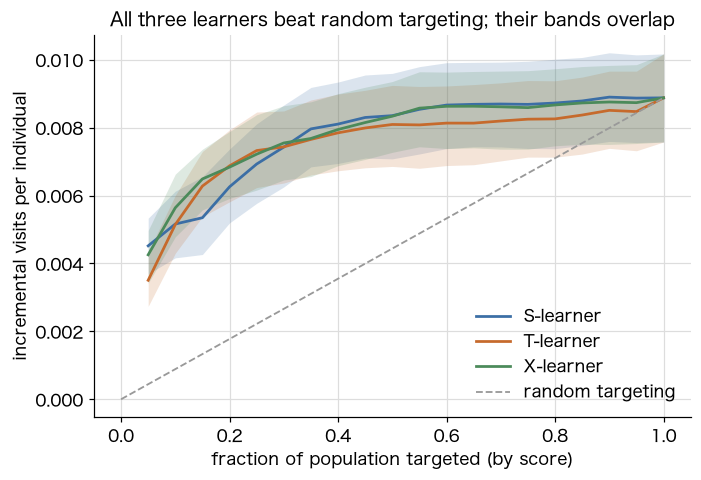

In [10]:
if HAS_DATA:
    bands = {
        name: bootstrap_curve_band(
            qini_curve, y_test, t_test, score, n_boot=max(N_BOOT // 2, 30), seed=SEED
        )
        for name, score in scores.items()
    }
    ax = plot_curves_with_bands(
        bands,
        title="All three learners beat random targeting; their bands overlap",
        ylabel="incremental visits per individual",
        diagonal_from="S-learner",
    )
    ax.figure.savefig("../assets/qini_criteo.png", dpi=200, bbox_inches="tight")

## 7. Calibration: uplift by decile

Deciles are formed on the predicted uplift; bars show the observed
treated-minus-control visit rate per decile with normal-approximation 95%
error bars, dots the mean prediction. A well calibrated model shows bars
that decline like the dots do.


S-learner: top decile observed uplift 0.0595 (se 0.0056), bottom decile -0.0003

T-learner: top decile observed uplift 0.0596 (se 0.0055), bottom decile 0.0053

X-learner: top decile observed uplift 0.0650 (se 0.0054), bottom decile 0.0015


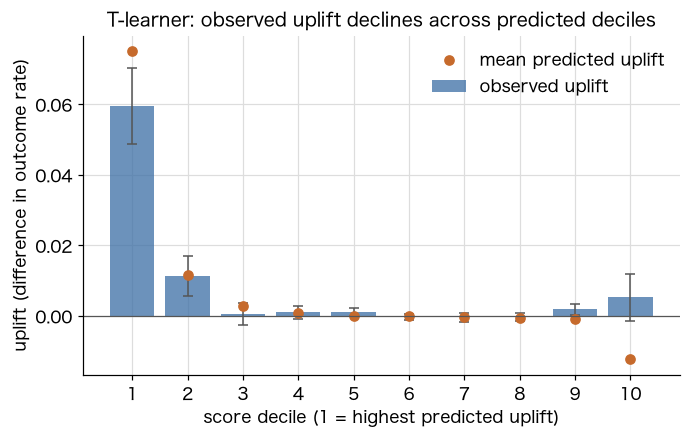

In [11]:
if HAS_DATA:
    for name in scores:
        table = uplift_by_decile(y_test, t_test, scores[name], n_bins=10)
        print(
            f"\n{name}: top decile observed uplift "
            f"{table['observed'].iloc[0]:.4f} (se {table['se'].iloc[0]:.4f}), "
            f"bottom decile {table['observed'].iloc[-1]:.4f}"
        )
    ax = plot_uplift_by_decile(
        uplift_by_decile(y_test, t_test, scores["T-learner"], n_bins=10),
        title="T-learner: observed uplift declines across predicted deciles",
    )

## 8. Honest reading of the results

What this benchmark supports, given the committed run:

- All three learners produce positive Qini coefficients whose CIs exclude
  zero: model-based targeting concentrates real incremental visits into the
  top of the ranking on this test set.
- Whether any learner beats another must be read from the paired-difference
  table in section 5, not from eyeballing overlapping marginal CIs. Where a
  paired CI covers zero, this data cannot rank that pair, and the honest
  summary is "no winner"; the notebook prints how many pairs separate.
- Effect sizes are small in absolute terms (the ATE on `visit` is about one
  percentage point), so business value depends entirely on volume and on
  the cost per targeted user, which this dataset does not contain.

What it does not support:

- No claim about `conversion` uplift; the outcome is too rare at this
  subsample size.
- No claim that the observed ordering of learners generalizes to other
  datasets, features or base models.

## Limitations

- Single train/test split and a single 1M-row subsample; a full study would
  repeat over multiple splits and subsamples. The bootstrap quantifies
  test-set sampling noise, not split-to-split variation.
- Features are anonymized, so no feature-level interpretation is possible.
- `visit` is a proxy outcome; visits are not profit, and an uplift model
  optimized for visits may not maximize revenue.
- Intent-to-treat effects only; `exposure` is ignored by design.
- One base-model configuration, chosen for the rare outcome and validated
  on synthetic data; learner rankings can change with the base model.

## References

- Diemert, Betlei, Renaudin, Amini (2018). A Large Scale Benchmark for
  Uplift Modeling. AdKDD 2018.
- Kunzel, Sekhon, Bickel, Yu (2019). Metalearners for estimating
  heterogeneous treatment effects using machine learning. PNAS 116(10).
- Radcliffe (2007). Using control groups to target on predicted lift.
  Direct Marketing Analytics Journal.